<a href="https://colab.research.google.com/github/KeyHornO/Machine-Learning/blob/main/Week5_Supervised_ML_zT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 5: Building My First Supervised Machine Learning Model
## Predicting the thermoelectric figure of merit (zT) from composition and temperature

**Name:** Benson Njuguna

**Course project repo:** https://github.com/KeyHornO/Machine-Learning/tree/main

**Project context.** My project aims to use ML to help improve the thermoelectric performance of polycrystalline SnSe. For this assignment I use the public **ESTM experimental thermoelectric database** (Na & Chang, *npj Computational Materials*, 2022; GitHub `KRICT-DATA/SIMD`), because my own SnSe processing dataset has only 8 samples, which is too few to train and test a model fairly. The ESTM data has 5,205 experimental measurements of 880 materials.

**Plan:** (1) define target and features, (2) decide regression or classification, (3) split into train/test, (4) train two models, (5) predict and evaluate, (6) compare.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

URL = "https://raw.githubusercontent.com/KRICT-DATA/SIMD/main/dataset/estm.xlsx"
df = pd.read_excel(URL)
df.columns = ["formula", "T_K", "seebeck_uV_K", "sigma_S_m", "kappa_W_mK", "pf_W_mK2", "zT", "doi"]
print("Shape:", df.shape)
df.head()

Shape: (5205, 8)


,formula,T_K,seebeck_uV_K,sigma_S_m,kappa_W_mK,pf_W_mK2,zT,doi
0,BiSb(Se0.92Br0.08)3,300.0,-110.0,27766.0,0.63,0.000336,0.159985,10.1002/adfm.201806558
1,BiSb(Se0.92Br0.08)3,400.0,-138.0,23883.0,0.57,0.000455,0.319177,10.1002/adfm.201806558
2,BiSb(Se0.92Br0.08)3,500.0,-163.0,20850.0,0.53,0.000554,0.522607,10.1002/adfm.201806558
3,BiSb(Se0.92Br0.08)3,600.0,-181.0,19000.0,0.51,0.000622,0.732305,10.1002/adfm.201806558
4,BiSb(Se0.92Br0.08)3,700.0,-193.0,17925.0,0.50,0.000668,0.940000,10.1002/adfm.201806558


## 1. Target (output) and features (inputs)

- **Target (output):** `zT`, the thermoelectric figure of merit. Higher zT means a more efficient material.
- **Features (inputs):**
  - the **composition**, written as the fraction of each element in the formula (for example Sn0.97Na0.03Se gives Sn = 0.485, Na = 0.015, Se = 0.5), and
  - the **measurement temperature** `T_K`.

I deliberately **do not** use `seebeck_uV_K`, `sigma_S_m`, `kappa_W_mK` or `pf_W_mK2` as inputs. zT is calculated directly from them (zT = σS²T/κ), so using them would leak the answer and the model would not be learning anything useful. The aim is to predict zT from what a researcher knows *before* measuring a material.

In [2]:
# Convert each chemical formula into element fractions
TOKEN = re.compile(r"[A-Z][a-z]?|\d+\.?\d*|\.\d+|\(|\)")

def parse_formula(formula):
    """Return {element: amount}, handling parentheses such as (Sn0.9Pb0.1)Se."""
    s = formula.replace("[", "(").replace("]", ")").replace(" ", "")
    toks = TOKEN.findall(s)
    if "".join(toks) != s:
        return None
    stack, i = [{}], 0
    num = lambda t: re.fullmatch(r"\d+\.?\d*|\.\d+", t) is not None
    while i < len(toks):
        t = toks[i]
        if re.fullmatch(r"[A-Z][a-z]?", t):
            n = 1.0
            if i + 1 < len(toks) and num(toks[i + 1]):
                n = float(toks[i + 1]); i += 1
            stack[-1][t] = stack[-1].get(t, 0) + n
        elif t == "(":
            stack.append({})
        elif t == ")":
            if len(stack) < 2:
                return None
            n = 1.0
            if i + 1 < len(toks) and num(toks[i + 1]):
                n = float(toks[i + 1]); i += 1
            top = stack.pop()
            for el, v in top.items():
                stack[-1][el] = stack[-1].get(el, 0) + v * n
        else:
            return None
        i += 1
    return stack[0] if len(stack) == 1 and stack[0] else None

comp = df["formula"].apply(parse_formula)
print("Formulas that could not be parsed:", int(comp.isna().sum()))
df = df[comp.notna()].reset_index(drop=True)
comp = comp[comp.notna()].reset_index(drop=True)

fractions = pd.DataFrame([{el: v / sum(c.values()) for el, v in c.items()} for c in comp]).fillna(0.0)
X = pd.concat([fractions, df[["T_K"]]], axis=1)
y = df["zT"]
groups = df["formula"]          # used later so the same material is never in both train and test

print("Features X:", X.shape, "(", fractions.shape[1], "element columns + temperature )")
print("Target y:", y.shape)
X.head()

Formulas that could not be parsed: 0
Features X: (5205, 66) ( 65 element columns + temperature )
Target y: (5205,)


,Bi,Sb,Se,Br,Cu,Cd,Sn,In,Cl,Pb,...,Ru,Pd,Ta,Au,Cs,Tb,Dy,Ho,Lu,T_K
0,0.2,0.2,0.552,0.048,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,300.0
1,0.2,0.2,0.552,0.048,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,400.0
2,0.2,0.2,0.552,0.048,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,500.0
3,0.2,0.2,0.552,0.048,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,600.0
4,0.2,0.2,0.552,0.048,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,700.0


In [3]:
y.describe().round(3)

,zT
count,5205.000
mean,0.354
std,0.348
min,0.000
25%,0.078
50%,0.247
75%,0.534
max,2.278


## 2. Regression or classification?

This is a **regression** problem. The target, zT, is a **continuous number** (here between 0 and about 2.3), and I want to predict its value, not assign a category. Classification would be appropriate only if I changed the question to something like "is zT above 1 or not?".

## 3. Train/test split

Each material appears in the data at several temperatures (often 8 or more rows per material). If I split rows **randomly**, rows of the same material land in both training and test sets, so the model is partly tested on things it has already seen and the score looks better than it really is (I show this below).

So I split **by material (`formula`)**: 80% of materials are used for training and 20% are held out entirely for testing. This mimics the real use case, predicting a material the model has never seen.

In [4]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Training rows: {len(X_train)}  ({groups.iloc[train_idx].nunique()} materials)")
print(f"Test rows:     {len(X_test)}  ({groups.iloc[test_idx].nunique()} materials)")
print("Materials in both sets:", len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

Training rows: 4217  (704 materials)
Test rows:     988  (176 materials)
Materials in both sets: 0


## 4. Models

1. **Linear Regression**: a simple baseline. It assumes zT is a weighted sum of the inputs (a straight-line relationship).
2. **Random Forest Regressor**: an ensemble of many decision trees. It can capture curved, non-linear effects and interactions (for example, the way temperature and composition act together), which my earlier analysis suggested are important, since zT rises sharply only at high temperature.

In [5]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)               # train
    predictions[name] = model.predict(X_test) # predict on the unseen test materials
    print("Trained:", name)

Trained: Linear Regression
Trained: Random Forest


## 5. Evaluation

For regression I use three metrics:
- **MAE** (mean absolute error): the average size of the error, in zT units. Lower is better.
- **RMSE** (root mean squared error): like MAE but penalises large errors more. Lower is better.
- **R²**: the share of the variation in zT the model explains. 1 is perfect, 0 is no better than always predicting the mean, and negative is worse than that.

In [6]:
def evaluate(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

results = pd.DataFrame({name: evaluate(y_test, p) for name, p in predictions.items()}).T
print("Reference: always predicting the training mean gives MAE =",
      round(mean_absolute_error(y_test, np.full(len(y_test), y_train.mean())), 3))
results.round(3)

Reference: always predicting the training mean gives MAE = 0.262


,MAE,RMSE,R2
Linear Regression,0.234,0.366,-0.352
Random Forest,0.092,0.153,0.764


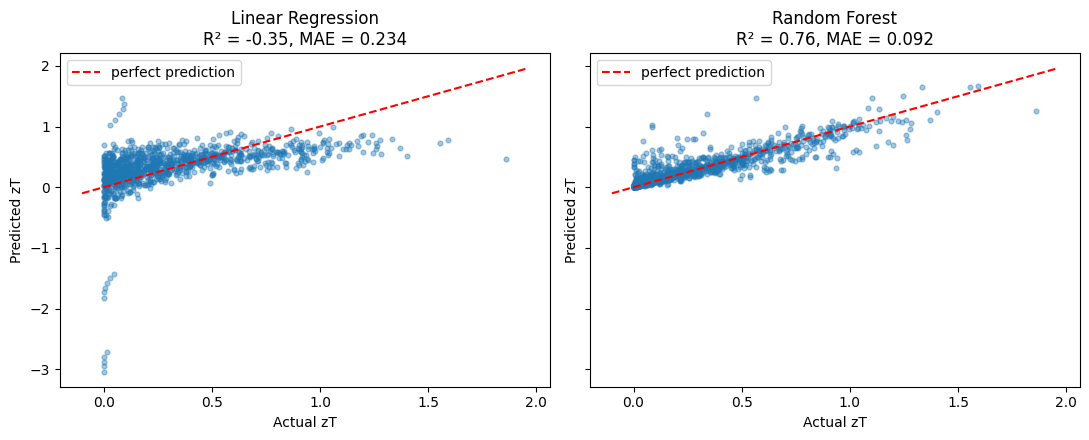

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
lim = [min(y_test.min(), -0.1), y_test.max() + 0.1]
for a, (name, p) in zip(ax, predictions.items()):
    a.scatter(y_test, p, alpha=0.4, s=12)
    a.plot(lim, lim, "r--", label="perfect prediction")
    a.set(xlabel="Actual zT", ylabel="Predicted zT",
          title=f"{name}\nR² = {r2_score(y_test, p):.2f}, MAE = {mean_absolute_error(y_test, p):.3f}")
    a.legend()
plt.tight_layout(); plt.show()

## 6. Extra checks

**(a) Why I split by material.** The same two models with an ordinary random row split:

In [8]:
tr, te = train_test_split(np.arange(len(df)), test_size=0.2, random_state=42)
rows = {}
for name, model in {"Linear Regression": LinearRegression(),
                    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)}.items():
    model.fit(X.iloc[tr], y.iloc[tr])
    rows[name] = evaluate(y.iloc[te], model.predict(X.iloc[te]))
print("Random row split (materials appear in both train and test):")
pd.DataFrame(rows).T.round(3)

Random row split (materials appear in both train and test):


,MAE,RMSE,R2
Linear Regression,0.195,0.257,0.435
Random Forest,0.072,0.116,0.885


**(b) Which inputs does the Random Forest rely on?**

In [9]:
rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
importance.head(10).round(3)

,0
T_K,0.305
Te,0.073
Sb,0.071
O,0.067
Ge,0.054
Ag,0.048
Cu,0.038
Pb,0.037
Mg,0.034
Sn,0.033


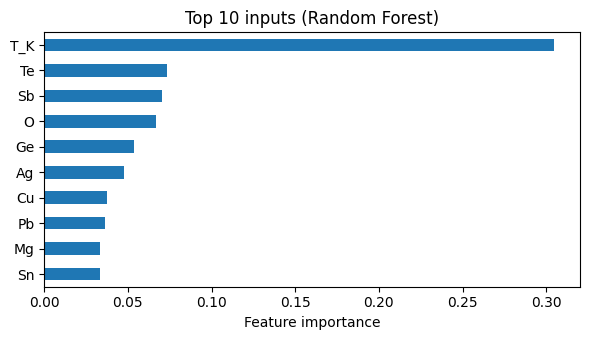

In [10]:
importance.head(10)[::-1].plot.barh(figsize=(6, 3.5))
plt.xlabel("Feature importance"); plt.title("Top 10 inputs (Random Forest)")
plt.tight_layout(); plt.show()

## 7. Comparison and discussion

**Results on unseen test materials (split by material)**

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear Regression | 0.234 | 0.366 | −0.352 |
| Random Forest | 0.092 | 0.153 | 0.764 |

**Which model is better?** The Random Forest is clearly better. Its average error (MAE 0.092) is about 2.5 times smaller than the linear model's (0.234), and it explains about 76% of the variation in zT on materials it has never seen.

**Why does Linear Regression do so poorly?**
- Its MAE (0.234) is only slightly better than simply predicting the average zT every time (0.262), and its R² is negative, meaning it is worse than that simple guess overall.
- zT depends on temperature and composition in a **curved, interacting** way (for example zT rises sharply only at high temperature, as my earlier analysis showed), and a straight-line model cannot represent that.
- For a few unusual compositions it makes extreme, physically impossible predictions (as low as about −3, when zT cannot be negative). A small number of these very large errors dominate RMSE and drive R² below zero.

**What the Random Forest relies on.** Temperature is by far the most important input (importance about 0.31), which agrees with the strong correlation found in my earlier notebook. The next inputs are individual elements (Te, Sb, O, Ge, Ag), probably because they mark well-known thermoelectric material families. I have not checked this explanation, so it is a hypothesis.

**Why the split matters.** With an ordinary random row split, the same two models score higher (Random Forest R² = 0.885, Linear Regression R² = 0.435), because rows from the same material appear in both training and test sets. The material-based split gives the more honest estimate for my real use case, predicting a new material.

**Limitations and what this means for my project**
- Both models use only the **composition fractions and temperature**. They know nothing about texture, grain size or processing route, which are the focus of my SnSe research.
- An error of about 0.09 zT is too large to separate close processing variants. In my own work the difference between my best hot-extruded and sintered samples was about 0.2 zT (0.64 versus 0.83). This model could not reliably rank such samples.
- This is a single train/test split with untuned models, so the numbers could change with a different split. Many test materials are also close relatives of training materials (for example doped versions of the same host), so a truly new chemistry would likely be harder.
- **Next steps:** use cross-validation grouped by material, tune the Random Forest and try gradient boosting, and add processing and microstructure inputs by combining this data with my own SnSe measurements.
